# Logistic Regression Model Optimization — Revised

**Stealth · Task 2203 · revision prepared October 20, 2026**

This revision responds to the [mentor feedback](../feedback/task-2203-mentor-feedback.md) on the [original submission](../model_optimation.ipynb). The original is preserved unchanged. This notebook adds evaluation, plots, and reproducibility fixes; it does not assume tuning will improve every metric.

| Feedback or issue | Revision |
| --- | --- |
| Expand visualizations | Confusion matrices, accuracy/F1 comparison, ROC curves, standardized coefficients, and split-sensitivity plot. |
| Check the 25% test split | Repeat the same recipe with a 25% holdout; report both splits. |
| Reduce dependence on one split | Nested cross-validation within the primary training set evaluates the complete tuning procedure. |
| Explain errors | Malignant-positive labels, error counts, and discussion of false negatives and false positives. |
| Run top to bottom | Consistent variable names, valid solver/penalty combinations, and recorded environment. |
| Prevent preprocessing leakage | Scaling inside a Pipeline, fitted separately in every CV fold. |

## Evaluation plan

These choices are fixed before held-out evaluation: seed 42, stratified 80/20 primary split, five-fold inner and outer CV, accuracy-based selection, the grid below, and the classifier's default prediction rule (equivalent to a 0.5 probability threshold apart from tie handling).

Accuracy continues the original project's objective. Malignant precision, recall, F1, and ROC AUC are also reported. No parameters or thresholds are selected from test results. The secondary 75/25 experiment is descriptive: both experiments reuse observations and are not independent validations.

In [1]:
from pathlib import Path
import importlib.metadata as metadata
import json
import platform
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
from sklearn.datasets import load_breast_cancer
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    RocCurveDisplay, make_scorer,
)
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, GridSearchCV, cross_validate, ParameterGrid,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('error', category=ConvergenceWarning)
SEED = 42
ARTIFACTS = Path('artifacts')
ARTIFACTS.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 120, 'savefig.dpi': 180, 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})
COLORS = {'Baseline': '#507c9d', 'Tuned': '#a53b4a'}
versions = {'python': platform.python_version()}
for package in ['numpy', 'pandas', 'scipy', 'matplotlib', 'scikit-learn',
                'nbformat', 'nbclient', 'nbconvert', 'ipykernel']:
    versions[package] = metadata.version(package)
(ARTIFACTS / 'environment.json').write_text(json.dumps(versions, indent=2))
display(pd.Series(versions, name='Executed environment').to_frame())

,Executed environment
python,3.13.9
numpy,2.3.5
pandas,2.3.3
scipy,1.16.3
matplotlib,3.10.6
scikit-learn,1.7.2
nbformat,5.10.4
nbclient,0.10.2
nbconvert,7.16.6
ipykernel,6.31.0


## 1. Data and class meaning

The built-in Breast Cancer Wisconsin (Diagnostic) dataset contains 569 observations and 30 numeric features. Original labels are 0 = malignant and 1 = benign. Here, **malignant is recoded to 1** and benign to 0, so recall, F1, positive-class probabilities, and false negatives all refer to malignant cases.

This is an educational classification benchmark. Its test performance does not establish clinical performance or justify diagnostic use.

In [2]:
data = load_breast_cancer(as_frame=True)
X = data.data
y = pd.Series((data.target == 0).astype(int), index=X.index, name='malignant')
assert list(data.target_names) == ['malignant', 'benign']
assert X.shape == (569, 30) and int(y.sum()) == 212
assert not X.isna().any().any()
display(y.value_counts().sort_index().rename(index={0: 'Benign (0)', 1: 'Malignant (1)'}).rename('Count').to_frame())
display(X.assign(malignant=y).head())
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y,
)
assert set(X_train.index).isdisjoint(X_test.index)
display(pd.DataFrame({
    'Partition': ['Training', 'Held-out test'],
    'Observations': [len(y_train), len(y_test)],
    'Malignant': [int(y_train.sum()), int(y_test.sum())],
    'Benign': [int((y_train == 0).sum()), int((y_test == 0).sum())],
}))
pd.DataFrame({'sample_index': X.index,
    'partition': np.where(X.index.isin(X_train.index), 'train', 'test'),
    'malignant': y,
}).to_csv(ARTIFACTS / 'primary_split.csv', index=False)

,Count
malignant,
Benign (0),357
Malignant (1),212


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,malignant
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


,Partition,Observations,Malignant,Benign
0,Training,455,170,285
1,Held-out test,114,42,72


## 2. Baseline and valid tuning grid

The baseline uses standardized features and L2 logistic regression (C=1, lbfgs solver). Scaling is fitted on training observations only. During CV, the pipeline fits a separate scaler in each fold.

The 15-configuration grid tests five C values, L1/L2 with liblinear, and L2 with lbfgs. Smaller C means stronger regularization. These combinations follow the **scikit-learn 1.7.2** API used here. In that version, l1_ratio applies only to elastic-net regularization; it is not used in this grid.

In [3]:
def make_baseline():
    return Pipeline([
        ('scaler', StandardScaler()),
        ('model', LogisticRegression(solver='lbfgs', penalty='l2', C=1.0,
                                     max_iter=10000, random_state=SEED)),
    ])

PARAM_GRID = [
    {'model__C': [0.01, 0.1, 1, 10, 100],
     'model__solver': ['liblinear'], 'model__penalty': ['l1', 'l2']},
    {'model__C': [0.01, 0.1, 1, 10, 100],
     'model__solver': ['lbfgs'], 'model__penalty': ['l2']},
]
SCORING = {
    'accuracy': 'accuracy',
    'precision_malignant': make_scorer(precision_score, pos_label=1, zero_division=0),
    'recall_malignant': make_scorer(recall_score, pos_label=1, zero_division=0),
    'f1_malignant': make_scorer(f1_score, pos_label=1, zero_division=0),
    'roc_auc': 'roc_auc',
}
def make_search():
    return GridSearchCV(
        make_baseline(), PARAM_GRID, scoring=SCORING, refit='accuracy',
        cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED),
        n_jobs=1, error_score='raise', return_train_score=False,
    )
assert len(list(ParameterGrid(PARAM_GRID))) == 15
display(pd.DataFrame(list(ParameterGrid(PARAM_GRID))))

,model__C,model__penalty,model__solver
0,0.01,l1,liblinear
1,0.01,l2,liblinear
2,0.10,l1,liblinear
3,0.10,l2,liblinear
4,1.00,l1,liblinear
5,1.00,l2,liblinear
6,10.00,l1,liblinear
7,10.00,l2,liblinear
8,100.00,l1,liblinear
9,100.00,l2,liblinear


## 3. Development estimate: nested cross-validation

Five outer folds are drawn **only from the 80% training partition**. Each outer fold runs a fresh five-fold search on its training observations. The outer validation fold evaluates the complete tuning procedure. The fixed baseline uses exactly the same outer folds.

This reduces the selection bias of reporting the best inner-CV score as final performance. Fold means and standard deviations summarize variation; a fold SD is **not a confidence interval**. The held-out 20% test set is not used here.

In [4]:
outer_folds = list(StratifiedKFold(
    n_splits=5, shuffle=True, random_state=SEED + 1,
).split(X_train, y_train))
cv_rows = []
for name, estimator in [('Baseline', make_baseline()), ('Tuned', make_search())]:
    scores = cross_validate(
        estimator, X_train, y_train, cv=outer_folds, scoring=SCORING,
        n_jobs=1, error_score='raise', return_estimator=True,
    )
    for fold in range(5):
        row = {'model': name, 'fold': fold + 1}
        row.update({metric: float(scores['test_' + metric][fold]) for metric in SCORING})
        if name == 'Tuned':
            row['selected_parameters'] = json.dumps(scores['estimator'][fold].best_params_, sort_keys=True)
        cv_rows.append(row)
cv_results = pd.DataFrame(cv_rows)
cv_results.to_csv(ARTIFACTS / 'nested_cv_folds.csv', index=False)
cv_summary = cv_results.groupby('model')[list(SCORING)].agg(['mean', 'std'])
cv_summary.to_csv(ARTIFACTS / 'nested_cv_summary.csv')
display(cv_summary.round(4))

accuracy         precision_malignant        recall_malignant          \
             mean     std                mean    std             mean     std   
model                                                                           
Baseline   0.9714  0.0125              0.9770  0.024           0.9471  0.0483   
Tuned      0.9670  0.0155              0.9717  0.034           0.9412  0.0550   

         f1_malignant         roc_auc          
                 mean     std    mean     std  
model                                          
Baseline       0.9608  0.0181  0.9951  0.0046  
Tuned          0.9548  0.0220  0.9948  0.0043

## 4. Final fit and held-out evaluation

The baseline is fitted on all primary training observations, and the tuned model performs its final search on the same training set. Both fitted models are then evaluated on the held-out 20% test set. The inner selection score is recorded separately from outer-CV and held-out results.

In [5]:
baseline = make_baseline().fit(X_train, y_train)
search = make_search().fit(X_train, y_train)
tuned = search.best_estimator_
models = {'Baseline': baseline, 'Tuned': tuned}
pd.DataFrame(search.cv_results_).to_csv(ARTIFACTS / 'primary_grid_search.csv', index=False)
print('Selected parameters:', search.best_params_)
print(f'Inner-CV selection accuracy (not final performance): {search.best_score_:.4f}')

def evaluate(estimator, features, target):
    prediction = estimator.predict(features)
    malignant_column = int(np.flatnonzero(estimator.classes_ == 1)[0])
    probability = estimator.predict_proba(features)[:, malignant_column]
    tn, fp, fn, tp = confusion_matrix(target, prediction, labels=[0, 1]).ravel()
    metrics = {
        'accuracy': accuracy_score(target, prediction),
        'precision_malignant': precision_score(target, prediction, zero_division=0),
        'recall_malignant': recall_score(target, prediction, zero_division=0),
        'f1_malignant': f1_score(target, prediction, zero_division=0),
        'roc_auc': roc_auc_score(target, probability),
        'specificity_benign': tn / (tn + fp),
        'true_negative': int(tn), 'false_positive': int(fp),
        'false_negative': int(fn), 'true_positive': int(tp),
        'test_n': len(target),
    }
    return metrics, prediction, probability

primary_results, predictions, probabilities = {}, {}, {}
for name, estimator in models.items():
    result, prediction, probability = evaluate(estimator, X_test, y_test)
    primary_results[name] = result
    predictions[name], probabilities[name] = prediction, probability
    report = pd.DataFrame(classification_report(
        y_test, prediction, labels=[0, 1], target_names=['Benign (0)', 'Malignant (1)'],
        output_dict=True, zero_division=0,
    )).T
    display(Markdown(f'**{name}: held-out classification report**'))
    display(report.round(4))
    report.to_csv(ARTIFACTS / f'{name.lower()}_classification_report.csv')
    assert sum(result[k] for k in ['true_negative', 'false_positive', 'false_negative', 'true_positive']) == len(y_test)
primary_table = pd.DataFrame(primary_results).T.rename_axis('model')
primary_table.to_csv(ARTIFACTS / 'primary_test_metrics.csv')
display(primary_table.round(4))
prediction_table = pd.DataFrame({'sample_index': X_test.index, 'actual_malignant': y_test.to_numpy()})
for name in models:
    prediction_table[f'{name.lower()}_prediction'] = predictions[name]
    prediction_table[f'{name.lower()}_probability_malignant'] = probabilities[name]
prediction_table.to_csv(ARTIFACTS / 'primary_test_predictions.csv', index=False)

Selected parameters: {'model__C': 0.1, 'model__penalty': 'l2', 'model__solver': 'liblinear'}
Inner-CV selection accuracy (not final performance): 0.9736


**Baseline: held-out classification report**

,precision,recall,f1-score,support
Benign (0),0.9595,0.9861,0.9726,72.0000
Malignant (1),0.9750,0.9286,0.9512,42.0000
accuracy,0.9649,0.9649,0.9649,0.9649
macro avg,0.9672,0.9573,0.9619,114.0000
weighted avg,0.9652,0.9649,0.9647,114.0000


**Tuned: held-out classification report**

,precision,recall,f1-score,support
Benign (0),0.9730,1.0000,0.9863,72.0000
Malignant (1),1.0000,0.9524,0.9756,42.0000
accuracy,0.9825,0.9825,0.9825,0.9825
macro avg,0.9865,0.9762,0.9810,114.0000
weighted avg,0.9829,0.9825,0.9824,114.0000


,accuracy,precision_malignant,recall_malignant,f1_malignant,roc_auc,specificity_benign,true_negative,false_positive,false_negative,true_positive,test_n
model,,,,,,,,,,,
Baseline,0.9649,0.975,0.9286,0.9512,0.9960,0.9861,71.0,1.0,3.0,39.0,114.0
Tuned,0.9825,1.000,0.9524,0.9756,0.9977,1.0000,72.0,0.0,2.0,40.0,114.0


## 5. Confusion matrices and classification errors

Rows show actual classes; columns show predictions. A **false negative** is a malignant observation predicted benign. A **false positive** is a benign observation predicted malignant. Accuracy alone does not distinguish these error types. Malignant recall and the false-negative count make missed malignant cases visible; a false positive represents an unnecessary malignant flag.

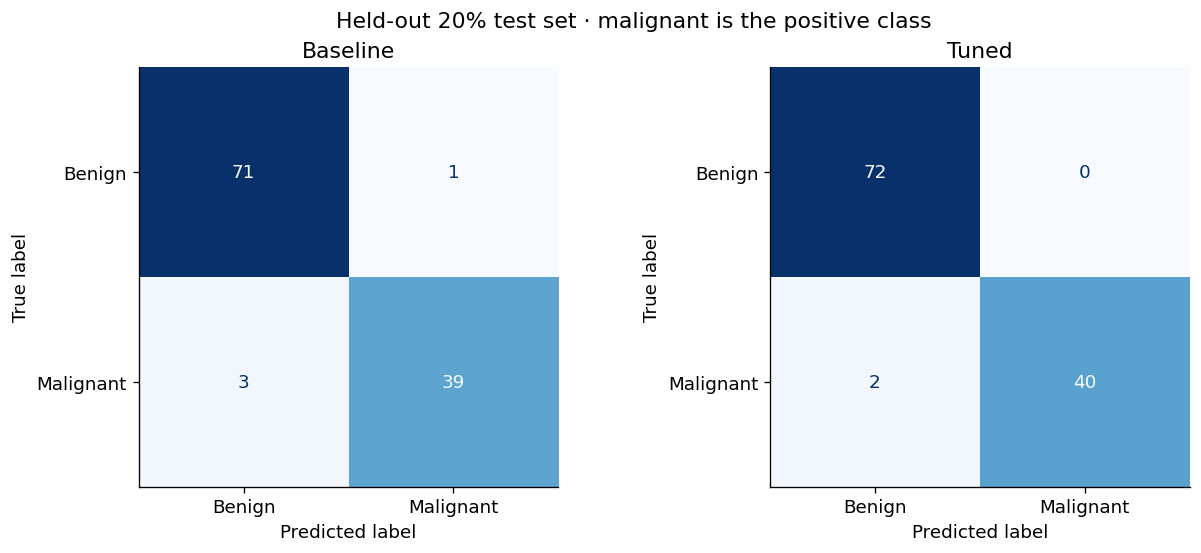

**Baseline:** 3 malignant case(s) predicted benign; 1 benign case(s) predicted malignant. Malignant recall: 92.86%.

**Tuned:** 2 malignant case(s) predicted benign; 0 benign case(s) predicted malignant. Malignant recall: 95.24%.

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.5), constrained_layout=True)
for ax, (name, prediction) in zip(axes, predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, prediction, labels=[0, 1], display_labels=['Benign', 'Malignant'],
        cmap='Blues', colorbar=False, ax=ax, values_format='d',
    )
    ax.set_title(name)
fig.suptitle('Held-out 20% test set · malignant is the positive class')
fig.savefig(ARTIFACTS / '01_confusion_matrices.png', bbox_inches='tight')
plt.show()
for name, r in primary_results.items():
    display(Markdown(
        f"**{name}:** {r['false_negative']} malignant case(s) predicted benign; "
        f"{r['false_positive']} benign case(s) predicted malignant. "
        f"Malignant recall: {r['recall_malignant']:.2%}."
    ))

## 6. Accuracy, malignant F1, and ROC curves

The bars compare both models on the same held-out observations. ROC curves use malignant probabilities and show the trade-off across thresholds. No threshold is selected using these test curves.

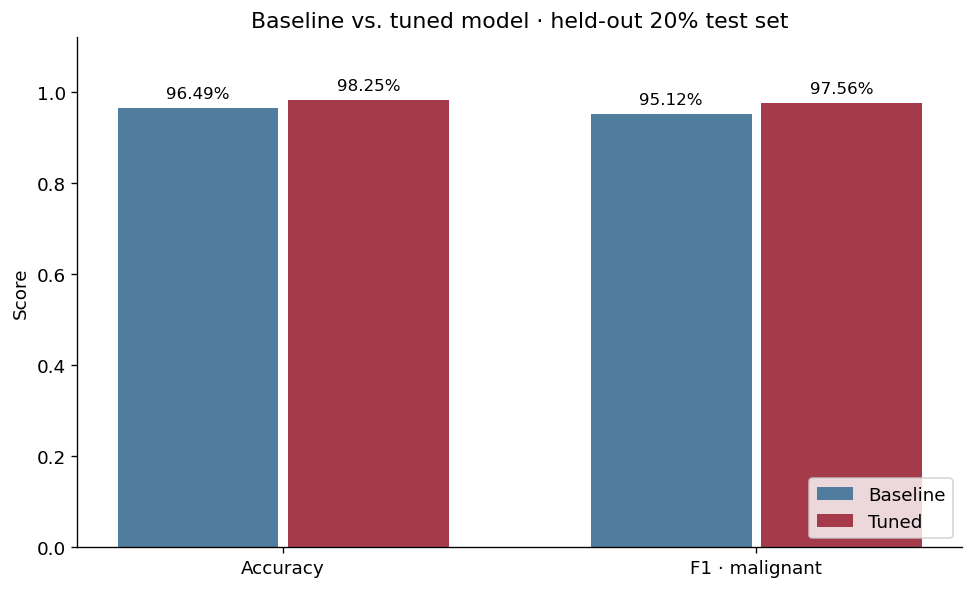

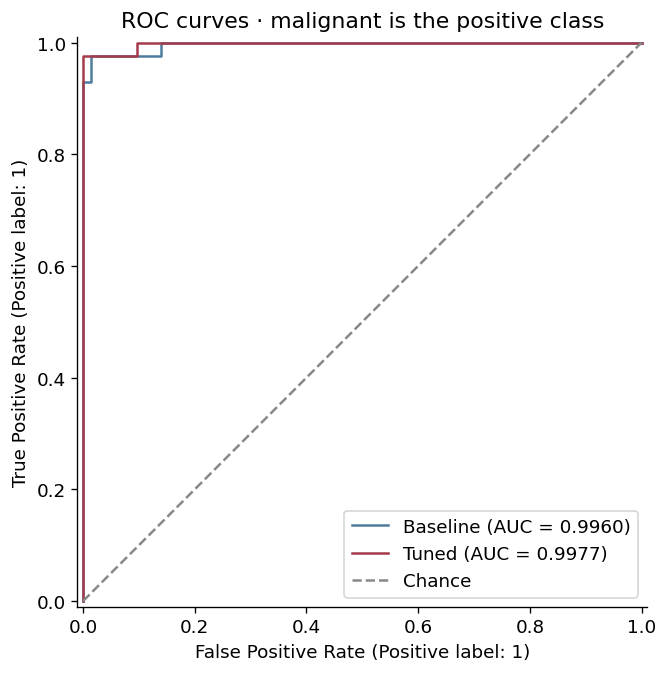

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.8), constrained_layout=True)
metric_names = ['accuracy', 'f1_malignant']
positions = np.arange(len(metric_names))
for offset, name in [(-0.18, 'Baseline'), (0.18, 'Tuned')]:
    values = primary_table.loc[name, metric_names].to_numpy(dtype=float)
    bars = ax.bar(positions + offset, values, width=0.34, color=COLORS[name], label=name)
    ax.bar_label(bars, labels=[f'{v:.2%}' for v in values], padding=4, fontsize=10)
ax.set_xticks(positions, ['Accuracy', 'F1 · malignant'])
ax.set_ylim(0, 1.12)
ax.set_ylabel('Score')
ax.set_title('Baseline vs. tuned model · held-out 20% test set')
ax.legend(loc='lower right')
fig.savefig(ARTIFACTS / '02_accuracy_f1.png', bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(6.5, 5.5), constrained_layout=True)
for name in models:
    RocCurveDisplay.from_predictions(
        y_test, probabilities[name], pos_label=1, name=name, curve_kwargs={'color': COLORS[name]}, ax=ax,
    )
    ax.lines[-1].set_label(f"{name} (AUC = {primary_results[name]['roc_auc']:.4f})")
ax.plot([0, 1], [0, 1], '--', color='#888888', label='Chance')
ax.set_title('ROC curves · malignant is the positive class')
ax.legend(loc='lower right')
fig.savefig(ARTIFACTS / '03_roc_curves.png', bbox_inches='tight')
plt.show()

## 7. Standardized coefficients

The 12 largest coefficients by absolute value are shown. Each describes the change in predicted malignant log-odds for a one-training-standard-deviation increase in the feature, holding other features fixed. Positive values push toward malignant predictions; negative values push toward benign predictions. These are model associations, not causal effects. Correlated features can make individual coefficient magnitudes unstable.

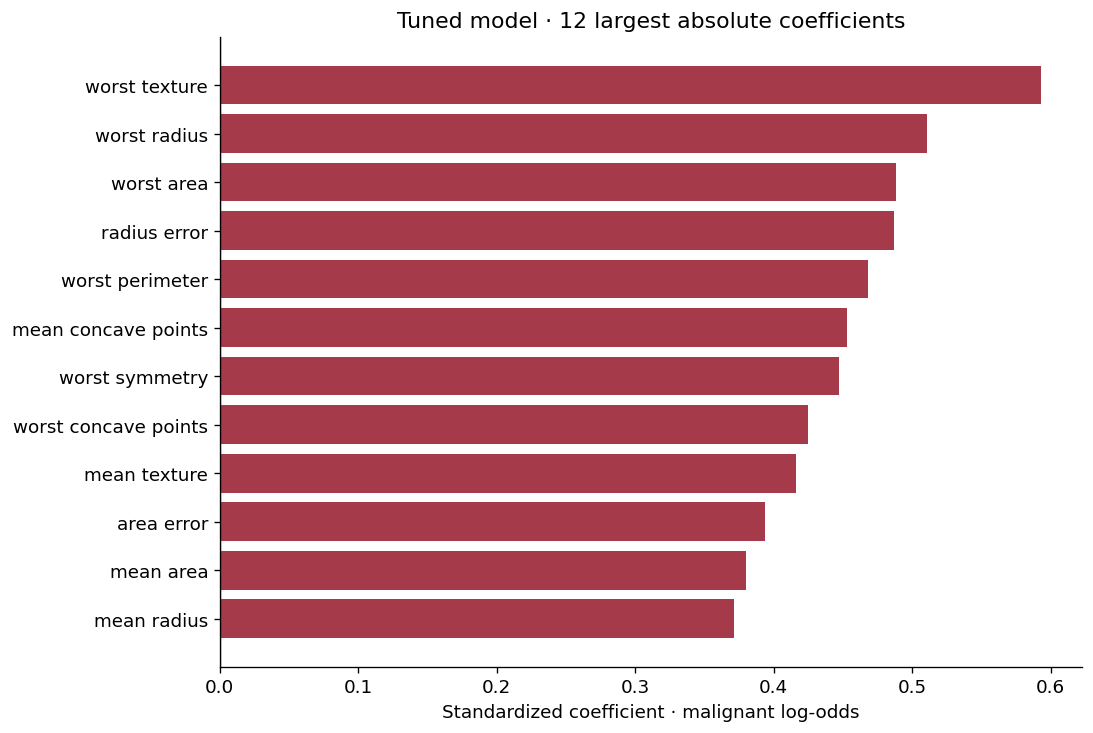

In [8]:
coefficients = pd.Series(tuned.named_steps['model'].coef_[0], index=X.columns, name='coefficient')
coefficients.rename_axis('feature').to_csv(ARTIFACTS / 'standardized_coefficients.csv')
largest = coefficients.loc[coefficients.abs().nlargest(12).index].sort_values()
fig, ax = plt.subplots(figsize=(9, 6), constrained_layout=True)
ax.barh(largest.index, largest.values, color=['#a53b4a' if v > 0 else '#507c9d' for v in largest])
ax.axvline(0, color='#444444', linewidth=0.8)
ax.set_xlabel('Standardized coefficient · malignant log-odds')
ax.set_title('Tuned model · 12 largest absolute coefficients')
fig.savefig(ARTIFACTS / '04_standardized_coefficients.png', bbox_inches='tight')
plt.show()

## 8. Sensitivity check: 25% test size

Repeat the fixed recipe with a stratified 75/25 split and seed 42. This changes both training and test observations. It is a limited sensitivity check, not independent validation or evidence across many seeds. Neither experiment is selected because it scores better. The primary 80/20 experiment and its nested-CV results remain the main evaluation.

,test_fraction,model,test_n,accuracy,recall_malignant,f1_malignant,false_negative,false_positive
0,0.20,Baseline,114,0.9649,0.9286,0.9512,3,1
1,0.20,Tuned,114,0.9825,0.9524,0.9756,2,0
2,0.25,Baseline,143,0.9650,0.9245,0.9515,4,1
3,0.25,Tuned,143,0.9720,0.9434,0.9615,3,1


25% split selected parameters: {'model__C': 1, 'model__penalty': 'l1', 'model__solver': 'liblinear'}


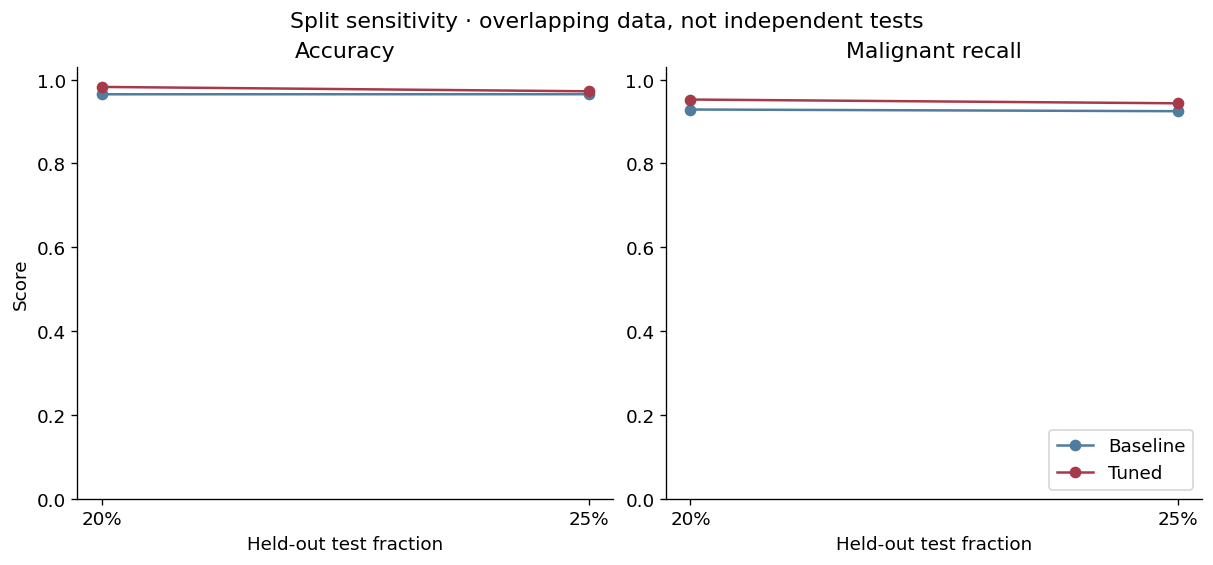

In [9]:
X_train_25, X_test_25, y_train_25, y_test_25 = train_test_split(
    X, y, test_size=0.25, random_state=SEED, stratify=y,
)
assert set(X_train_25.index).isdisjoint(X_test_25.index)
baseline_25 = make_baseline().fit(X_train_25, y_train_25)
search_25 = make_search().fit(X_train_25, y_train_25)
sensitivity_rows = [dict(model=name, test_fraction=0.20, **r) for name, r in primary_results.items()]
for name, estimator in [('Baseline', baseline_25), ('Tuned', search_25.best_estimator_)]:
    result, _, _ = evaluate(estimator, X_test_25, y_test_25)
    sensitivity_rows.append(dict(model=name, test_fraction=0.25, **result))
sensitivity = pd.DataFrame(sensitivity_rows)
sensitivity.to_csv(ARTIFACTS / 'split_sensitivity.csv', index=False)
pd.DataFrame(search_25.cv_results_).to_csv(ARTIFACTS / 'sensitivity_grid_search.csv', index=False)
pd.DataFrame({'sample_index': X.index,
    'partition': np.where(X.index.isin(X_train_25.index), 'train', 'test'),
    'malignant': y,
}).to_csv(ARTIFACTS / 'sensitivity_split.csv', index=False)
display(sensitivity[['test_fraction', 'model', 'test_n', 'accuracy', 'recall_malignant',
                     'f1_malignant', 'false_negative', 'false_positive']].round(4))
print('25% split selected parameters:', search_25.best_params_)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.6), constrained_layout=True)
for ax, metric, title in zip(axes, ['accuracy', 'recall_malignant'], ['Accuracy', 'Malignant recall']):
    for name in models:
        subset = sensitivity[sensitivity.model == name].sort_values('test_fraction')
        ax.plot(subset.test_fraction * 100, subset[metric], marker='o', label=name, color=COLORS[name])
    ax.set_xticks([20, 25], ['20%', '25%'])
    ax.set_xlabel('Held-out test fraction')
    ax.set_ylim(0, 1.03)
    ax.set_title(title)
axes[0].set_ylabel('Score')
axes[1].legend(loc='lower right')
fig.suptitle('Split sensitivity · overlapping data, not independent tests')
fig.savefig(ARTIFACTS / '05_split_sensitivity.png', bbox_inches='tight')
plt.show()

## 9. Results and limitations

The summary below is generated from this execution. The original saved scores are historical records, not a controlled comparison: stratification, class coding, folds, preprocessing, and the grid differ. Report observed results, including ties or metrics that do not improve.

In [10]:
b, t = primary_results['Baseline'], primary_results['Tuned']
delta = 100 * (t['accuracy'] - b['accuracy'])
cv_b = cv_summary.loc['Baseline', ('accuracy', 'mean')]
cv_t = cv_summary.loc['Tuned', ('accuracy', 'mean')]
summary = f"""### Observed results

- **Primary held-out accuracy:** baseline {b['accuracy']:.2%}; tuned {t['accuracy']:.2%} ({delta:+.2f} percentage points).
- **Primary malignant recall:** baseline {b['recall_malignant']:.2%}; tuned {t['recall_malignant']:.2%}.
- **Missed malignant cases:** baseline {b['false_negative']}; tuned {t['false_negative']}, among {int(y_test.sum())} malignant test observations.
- **Nested-CV mean accuracy on the primary training partition:** baseline {cv_b:.2%}; tuned procedure {cv_t:.2%}. Fold standard deviations are in the development table.

### Interpretation limits

The dataset and test samples are small. These experiments do not demonstrate a general advantage for tuning, and the 25% split does not establish stability across datasets or seeds. Accuracy-based selection can prefer a configuration that does not maximize malignant recall. Threshold selection, probability calibration, repeated evaluation, and external validation would need separate development and validation plans. Coefficients describe the fitted model and do not establish causal effects.
"""
display(Markdown(summary))
(ARTIFACTS / 'results_summary.md').write_text(summary)
record = {
    'revision_date': '2026-10-20', 'seed': SEED, 'positive_class': 'malignant = 1',
    'primary_test_fraction': 0.20, 'sensitivity_test_fraction': 0.25,
    'selection_metric': 'accuracy', 'grid_configurations': len(list(ParameterGrid(PARAM_GRID))),
    'primary_best_parameters': search.best_params_,
    'sensitivity_best_parameters': search_25.best_params_,
    'primary_metrics': primary_results,
    'nested_cv_accuracy_mean': {'Baseline': cv_b, 'Tuned': cv_t},
}
(ARTIFACTS / 'run_summary.json').write_text(json.dumps(record, indent=2))
print('Completed: tables, figures, predictions, environment, and summary saved in artifacts/.')

### Observed results

- **Primary held-out accuracy:** baseline 96.49%; tuned 98.25% (+1.75 percentage points).
- **Primary malignant recall:** baseline 92.86%; tuned 95.24%.
- **Missed malignant cases:** baseline 3; tuned 2, among 42 malignant test observations.
- **Nested-CV mean accuracy on the primary training partition:** baseline 97.14%; tuned procedure 96.70%. Fold standard deviations are in the development table.

### Interpretation limits

The dataset and test samples are small. These experiments do not demonstrate a general advantage for tuning, and the 25% split does not establish stability across datasets or seeds. Accuracy-based selection can prefer a configuration that does not maximize malignant recall. Threshold selection, probability calibration, repeated evaluation, and external validation would need separate development and validation plans. Coefficients describe the fitted model and do not establish causal effects.


Completed: tables, figures, predictions, environment, and summary saved in artifacts/.


## References

- [scikit-learn 1.7: preprocessing and data leakage](https://scikit-learn.org/1.7/common_pitfalls.html)
- [scikit-learn 1.7: LogisticRegression compatibility](https://scikit-learn.org/1.7/modules/generated/sklearn.linear_model.LogisticRegression.html)
- [Nested versus non-nested cross-validation](https://scikit-learn.org/1.7/auto_examples/model_selection/plot_nested_cross_validation_iris.html)
- [Dataset and original label encoding](https://scikit-learn.org/1.7/modules/generated/sklearn.datasets.load_breast_cancer.html)